In [2]:
!pip install -q datasets

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Đã nạp thư viện")

Đã nạp thư viện


In [ ]:
print("Đag kéo dữ liệu....")
stream_ds = load_dataset("tinixai/vietnam-real-estates", split="train", streaming=True)
df_raw = pd.DataFrame(stream_ds)
print("Tải thành công")

def find_col(columns, keywords):
    for col in columns:
        for kw in keywords:
            if kw in col.lower():
                return col
    return None

col_area = find_col(df_raw.columns, ['area', 'dientich', 'diện tích', 'square', 'm2'])
col_price = find_col(df_raw.columns, ['price', 'gia', 'giá'])

def parse_area(val):
    if pd.isna(val): return np.nan
    match = re.search(r'(\d+[\.,]?\d*)', str(val).replace(',', '.'))
    return float(match.group(1)) if match else np.nan

def parse_price_to_million(row):
    val = row[col_price]
    area = row['Area_m2']
    if pd.isna(val): return np.nan
    s = str(val).lower().replace(',', '.').strip()

    if 'thỏa thuận' in s or 'thoa thuan' in s or 'liên hệ' in s:
        return np.nan

    match = re.search(r'(\d+\.?\d*)', s)
    if not match: return np.nan
    num = float(match.group(1))

    if 'tỷ' in s or 'ty' in s or 'billion' in s:
        return num * 1000.0
    elif 'triệu/m' in s or 'trieu/m' in s:
        return num * area if pd.notna(area) else np.nan
    elif 'triệu' in s or 'trieu' in s or 'million' in s:
        return num
    else:
        if num >= 1e6:
            return num / 1e6
        elif num < 100:
            return num * 1000.0
        else:
            return num

df_clean = df_raw.copy()
df_clean['Area_m2'] = df_clean[col_area].apply(parse_area)
df_clean['Price_Trieu'] = df_clean.apply(parse_price_to_million, axis=1)

df_clean = df_clean.dropna(subset=['Area_m2', 'Price_Trieu'])
df_clean = df_clean[(df_clean['Area_m2'] > 10) & (df_clean['Price_Trieu'] > 100)]

q_a_low, q_a_high = df_clean['Area_m2'].quantile([0.01, 0.99])
q_p_low, q_p_high = df_clean['Price_Trieu'].quantile([0.01, 0.99])

df_clean = df_clean[
    (df_clean['Area_m2'].between(q_a_low, q_a_high)) &
    (df_clean['Price_Trieu'].between(q_p_low, q_p_high))
]

print(f"Mẫu đã sạch sẵn sàng huấn luyện: {len(df_clean)} dòng.")
display(df_clean[['Area_m2', 'Price_Trieu']].describe())

Đag kéo dữ liệu....


README.md:   0%|          | 0.00/7.74k [00:00<?, ?B/s]

Tải thành công


In [ ]:
X = df_clean[['Area_m2']]
y = df_clean['Price_Trieu']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tập Train gốc: {len(X_train):,} dòng | Tập Test cố định: {len(X_test):,} dòng")

Tập Train gốc: 72,610 dòng | Tập Test cố định: 18,153 dòng


In [ ]:
sample_ratios = [0.005, 0.02, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
size_results = []

for ratio in sample_ratios:
    if ratio < 1.0:
        X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=ratio, random_state=42)
    else:
        X_sub, y_sub = X_train, y_train

    m = LinearRegression().fit(X_sub, y_sub)
    y_p = m.predict(X_test)
    size_results.append({
        'Tỷ lệ (%)': f"{ratio*100:.1f}%",
        'Số mẫu Train': len(X_sub),
        'Slope (Triệu/m2)': round(m.coef_[0], 2),
        'MSE': round(mean_squared_error(y_test, y_p), 2),
        'R2': round(r2_score(y_test, y_p), 4)
    })

df_size = pd.DataFrame(size_results)
print("=== BẢNG 1: KẾT QUẢ KHI THAY ĐỔI SỐ LƯỢNG MẪU ===")
display(df_size)

=== BẢNG 1: KẾT QUẢ KHI THAY ĐỔI SỐ LƯỢNG MẪU ===


,Tỷ lệ (%),Số mẫu Train,Slope (Triệu/m2),MSE,R2
0,0.5%,363,93.56,1.798105e+08,0.3237
1,2.0%,1452,99.38,1.791112e+08,0.3263
2,5.0%,3630,95.30,1.787145e+08,0.3278
3,10.0%,7261,94.39,1.786525e+08,0.3281
4,25.0%,18152,95.34,1.786545e+08,0.3280
5,50.0%,36305,96.38,1.786962e+08,0.3279
6,75.0%,54457,97.69,1.787742e+08,0.3276
7,100.0%,72610,96.39,1.786978e+08,0.3279


In [ ]:
noise_levels = [0.0, 0.5, 1.0, 1.5, 2.5, 4.0]
noise_results = []
models_noise = {}

np.random.seed(42)
y_std = y_train.std()

for lvl in noise_levels:
    noise = np.random.normal(loc=0, scale=y_std * lvl, size=len(y_train))
    y_train_noisy = y_train + noise

    m = LinearRegression().fit(X_train, y_train_noisy)
    models_noise[lvl] = m  # Lưu lại mô hình để Cell 3D lấy ra vẽ

    y_p = m.predict(X_test)
    noise_results.append({
        'Mức nhiễu (x std)': lvl,
        'Slope (Triệu/m2)': round(m.coef_[0], 2),
        'MSE': round(mean_squared_error(y_test, y_p), 2),
        'R2': round(r2_score(y_test, y_p), 4)
    })

df_noise = pd.DataFrame(noise_results)
print("=== BẢNG 2: KẾT QUẢ KHI TĂNG ĐỘ NHIỄU ===")
display(df_noise)

=== BẢNG 2: KẾT QUẢ KHI TĂNG ĐỘ NHIỄU ===


,Mức nhiễu (x std),Slope (Triệu/m2),MSE,R2
0,0.0,96.39,1.786978e+08,0.3279
1,0.5,97.16,1.787403e+08,0.3277
2,1.0,97.28,1.787424e+08,0.3277
3,1.5,96.49,1.787012e+08,0.3279
4,2.5,93.99,1.786394e+08,0.3281
5,4.0,99.12,1.788988e+08,0.3271


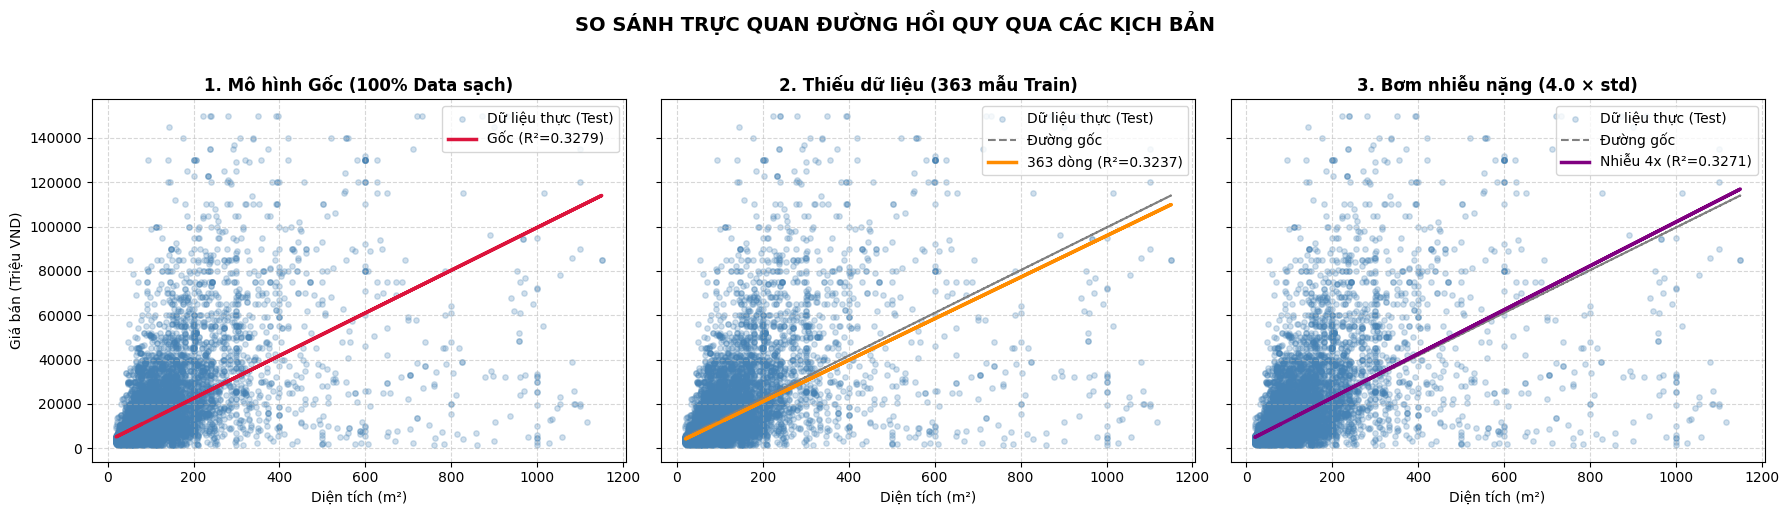

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

m_base = models_noise[0.0]

# 1. Mô hình gốc
axes[0].scatter(X_test, y_test, color='steelblue', alpha=0.25, s=15, label='Dữ liệu thực (Test)')
axes[0].plot(X_test, m_base.predict(X_test), color='crimson', lw=2.5, label=f'Gốc (R²={df_noise.iloc[0]["R2"]:.4f})')
axes[0].set_title('1. Mô hình Gốc (100% Data sạch)', fontweight='bold')
axes[0].set_xlabel('Diện tích (m²)')
axes[0].set_ylabel('Giá bán (Triệu VND)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Thiếu dữ liệu nặng (0.5%)
X_tiny, _, y_tiny, _ = train_test_split(X_train, y_train, train_size=0.005, random_state=42)
m_tiny = LinearRegression().fit(X_tiny, y_tiny)
axes[1].scatter(X_test, y_test, color='steelblue', alpha=0.25, s=15, label='Dữ liệu thực (Test)')
axes[1].plot(X_test, m_base.predict(X_test), color='gray', lw=1.5, linestyle='--', label='Đường gốc')
axes[1].plot(X_test, m_tiny.predict(X_test), color='darkorange', lw=2.5, label=f'{len(X_tiny)} dòng (R²={df_size.iloc[0]["R2"]:.4f})')
axes[1].set_title(f'2. Thiếu dữ liệu ({len(X_tiny)} mẫu Train)', fontweight='bold')
axes[1].set_xlabel('Diện tích (m²)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Nhiễu nặng (4.0 x std)
m_heavy = models_noise[4.0]
axes[2].scatter(X_test, y_test, color='steelblue', alpha=0.25, s=15, label='Dữ liệu thực (Test)')
axes[2].plot(X_test, m_base.predict(X_test), color='gray', lw=1.5, linestyle='--', label='Đường gốc')
axes[2].plot(X_test, m_heavy.predict(X_test), color='purple', lw=2.5, label=f'Nhiễu 4x (R²={df_noise.iloc[-1]["R2"]:.4f})')
axes[2].set_title('3. Bơm nhiễu nặng (4.0 × std)', fontweight='bold')
axes[2].set_xlabel('Diện tích (m²)')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('SO SÁNH TRỰC QUAN ĐƯỜNG HỒI QUY QUA CÁC KỊCH BẢN', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

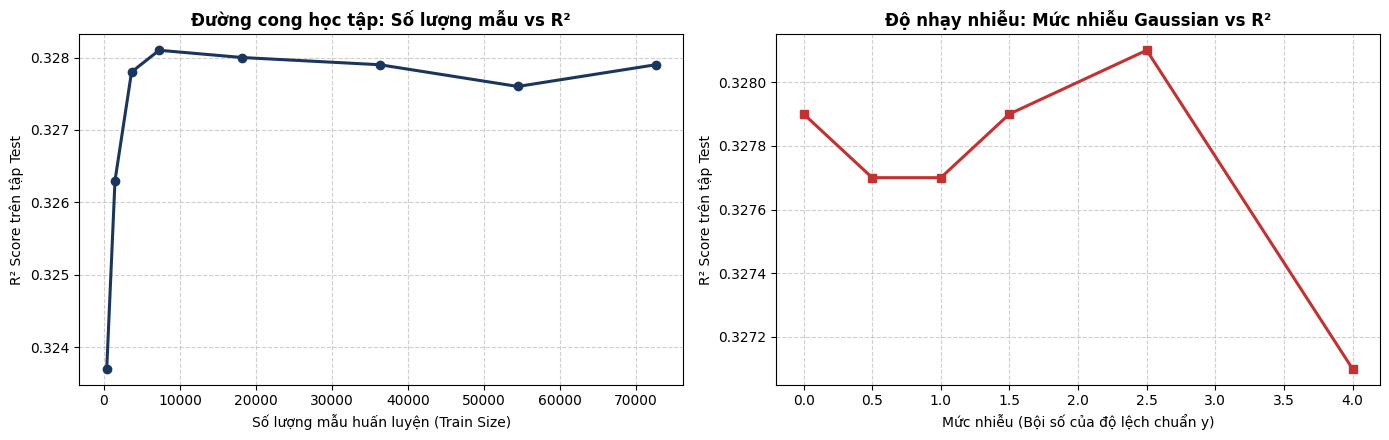

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Biểu đồ trái: Learning Curve
ax1.plot(df_size['Số mẫu Train'], df_size['R2'], marker='o', color='#1B365D', lw=2.2)
ax1.set_title('Đường cong học tập: Số lượng mẫu vs R²', fontweight='bold')
ax1.set_xlabel('Số lượng mẫu huấn luyện (Train Size)')
ax1.set_ylabel('R² Score trên tập Test')
ax1.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ phải: Noise Sensitivity
ax2.plot(df_noise['Mức nhiễu (x std)'], df_noise['R2'], marker='s', color='#C53030', lw=2.2)
ax2.set_title('Độ nhạy nhiễu: Mức nhiễu Gaussian vs R²', fontweight='bold')
ax2.set_xlabel('Mức nhiễu (Bội số của độ lệch chuẩn y)')
ax2.set_ylabel('R² Score trên tập Test')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
exclude_cols = [col_area, col_price, 'Area_m2', 'Price_Trieu']
extra_num_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

col_dist = find_col(df_clean.columns, ['district', 'quan', 'quận', 'huyen', 'ward', 'phuong'])

print(f"-> Các cột số bổ sung: {extra_num_cols}")
print(f"-> Cột vị trí (Quận/Huyện): {col_dist}")

selected_cols = ['Area_m2'] + extra_num_cols + ([col_dist] if col_dist else []) + ['Price_Trieu']
df_multi = df_clean[selected_cols].copy()

for col in extra_num_cols:
    df_multi[col] = df_multi[col].fillna(df_multi[col].median())

print(f"Kích thước bảng đa biến trước mã hóa: {df_multi.shape}")
display(df_multi.head(3))

-> Các cột số bổ sung: ['floor_count', 'frontage_width', 'house_depth', 'road_width', 'bedroom_count', 'bathroom_count']
-> Cột vị trí (Quận/Huyện): district_name
Kích thước bảng đa biến trước mã hóa: (90763, 9)


,Area_m2,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,district_name,Price_Trieu
0,80.0,3.0,4.0,14.0,6.0,3.0,2.0,7,6500.0
2,84.0,4.0,5.0,14.0,6.0,5.0,5.0,Bình Tân,7500.0
3,62.0,3.0,5.0,14.0,6.0,3.0,3.0,Bình Thạnh,2530.0


In [ ]:
if col_dist and col_dist in df_multi.columns:
    df_multi[col_dist] = df_multi[col_dist].fillna('Khac').astype(str).str.strip()
    top_dists = df_multi[col_dist].value_counts().nlargest(15).index
    df_multi[col_dist] = df_multi[col_dist].where(df_multi[col_dist].isin(top_dists), 'Khac')

    df_multi = pd.get_dummies(df_multi, columns=[col_dist], drop_first=True, dtype=int)

X_multi = df_multi.drop(columns=['Price_Trieu'])
y_multi = df_multi['Price_Trieu']

X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

print(f"Tổng số biến đầu vào sau mã hóa: {X_multi.shape[1]} biến")
print(f"Tập Train: {len(X_m_train):,} dòng | Tập Test: {len(X_m_test):,} dòng")

Tổng số biến đầu vào sau mã hóa: 21 biến
Tập Train: 72,610 dòng | Tập Test: 18,153 dòng


In [ ]:
model_s = LinearRegression().fit(X_m_train[['Area_m2']], y_m_train)
y_s_pred = model_s.predict(X_m_test[['Area_m2']])

model_m = LinearRegression().fit(X_m_train, y_m_train)
y_m_pred = model_m.predict(X_m_test)

compare_df = pd.DataFrame([
    {
        'Mô hình': '1. Hồi quy Đơn biến (Chỉ Diện tích)',
        'Số biến (Features)': 1,
        'MSE': round(mean_squared_error(y_m_test, y_s_pred), 2),
        'RMSE (Sai số TB - Triệu VND)': round(np.sqrt(mean_squared_error(y_m_test, y_s_pred)), 2),
        'R² Score': round(r2_score(y_m_test, y_s_pred), 4)
    },
    {
        'Mô hình': '2. Hồi quy Đa biến (Diện tích + Biến phụ + Quận)',
        'Số biến (Features)': X_multi.shape[1],
        'MSE': round(mean_squared_error(y_m_test, y_m_pred), 2),
        'RMSE (Sai số TB - Triệu VND)': round(np.sqrt(mean_squared_error(y_m_test, y_m_pred)), 2),
        'R² Score': round(r2_score(y_m_test, y_m_pred), 4)
    }
])

print("=== BẢNG SO SÁNH HIỆU NĂNG: ĐƠN BIẾN VS ĐA BIẾN ===")
display(compare_df)

=== BẢNG SO SÁNH HIỆU NĂNG: ĐƠN BIẾN VS ĐA BIẾN ===


,Mô hình,Số biến (Features),MSE,RMSE (Sai số TB - Triệu VND),R² Score
0,1. Hồi quy Đơn biến (Chỉ Diện tích),1,1.786978e+08,13367.79,0.3279
1,2. Hồi quy Đa biến (Diện tích + Biến phụ + Quận),21,1.552474e+08,12459.83,0.4161


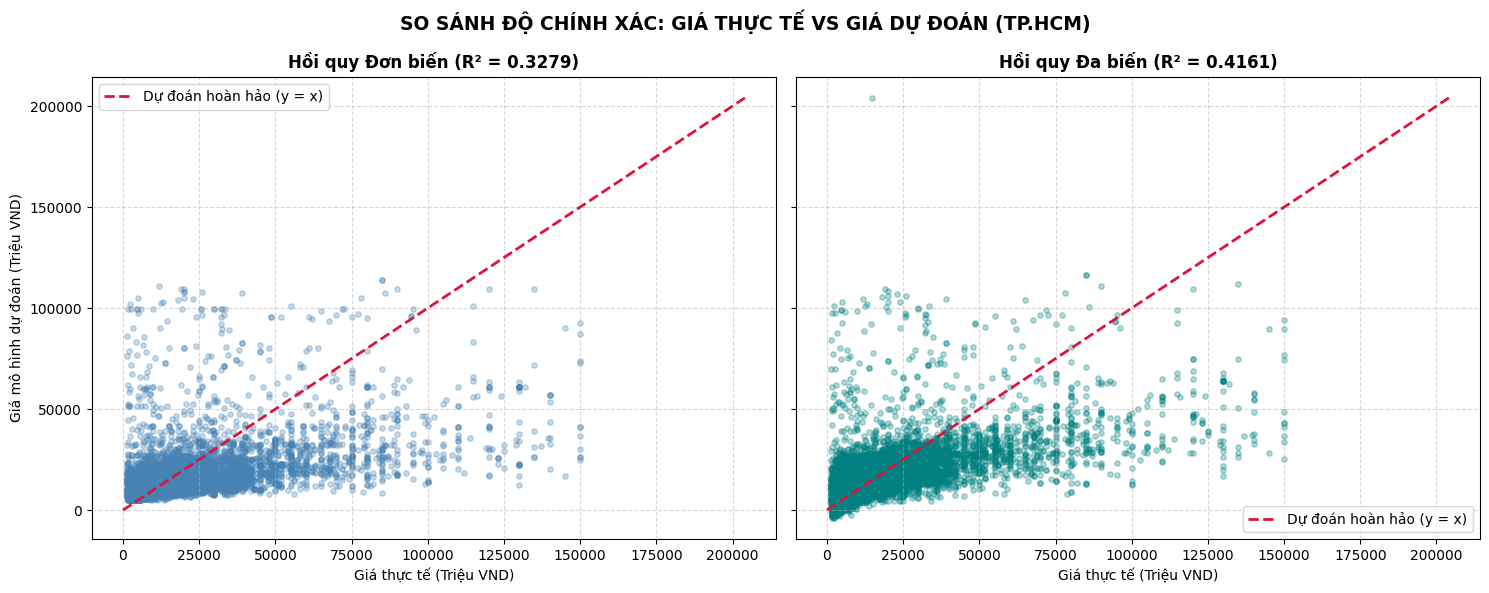

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

max_val = max(y_m_test.max(), y_m_pred.max())

ax1.scatter(y_m_test, y_s_pred, color='steelblue', alpha=0.3, s=15)
ax1.plot([0, max_val], [0, max_val], color='crimson', linestyle='--', lw=2, label='Dự đoán hoàn hảo (y = x)')
ax1.set_title(f'Hồi quy Đơn biến (R² = {compare_df.iloc[0]["R² Score"]})', fontweight='bold')
ax1.set_xlabel('Giá thực tế (Triệu VND)')
ax1.set_ylabel('Giá mô hình dự đoán (Triệu VND)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.scatter(y_m_test, y_m_pred, color='teal', alpha=0.3, s=15)
ax2.plot([0, max_val], [0, max_val], color='crimson', linestyle='--', lw=2, label='Dự đoán hoàn hảo (y = x)')
ax2.set_title(f'Hồi quy Đa biến (R² = {compare_df.iloc[1]["R² Score"]})', fontweight='bold')
ax2.set_xlabel('Giá thực tế (Triệu VND)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('SO SÁNH ĐỘ CHÍNH XÁC: GIÁ THỰC TẾ VS GIÁ DỰ ĐOÁN (TP.HCM)', fontsize=13.5, fontweight='bold')
plt.tight_layout()
plt.show()

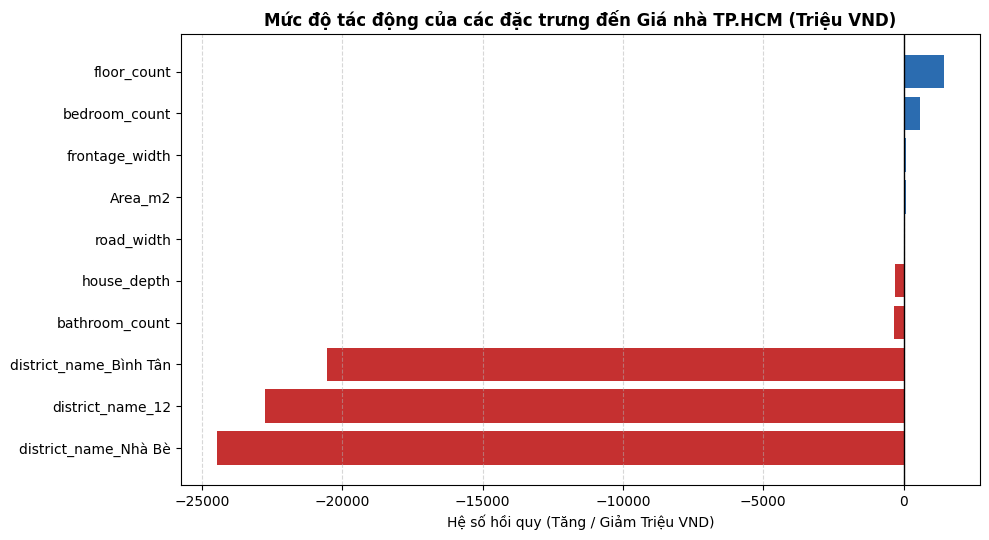

In [ ]:
coef_df = pd.DataFrame({
    'Đặc trưng': X_multi.columns,
    'Tác động (Triệu VND)': model_m.coef_
}).sort_values(by='Tác động (Triệu VND)', ascending=False)

top_impact = pd.concat([coef_df.head(7), coef_df.tail(3)]).drop_duplicates()
top_impact = top_impact.sort_values(by='Tác động (Triệu VND)', ascending=True)

plt.figure(figsize=(10, 5.5))
colors = ['#C53030' if x < 0 else '#2B6CB0' for x in top_impact['Tác động (Triệu VND)']]
plt.barh(top_impact['Đặc trưng'], top_impact['Tác động (Triệu VND)'], color=colors)
plt.axvline(0, color='black', lw=1)
plt.title('Mức độ tác động của các đặc trưng đến Giá nhà TP.HCM (Triệu VND)', fontweight='bold')
plt.xlabel('Hệ số hồi quy (Tăng / Giảm Triệu VND)')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()